# LDA Deck-Level Model
**Modeling — Deck Granularity**

Implements LDA at slide-deck level following the CRISP-DM modeling phase.  
Library: `tomotopy` (Collapsed Gibbs Sampling).  
Input: deck-level token lists produced by `src/utils.py`.  
Granularity: one document = one full slide deck (all pages of one lecture PDF aggregated).  
Corpus size: 9 documents (one per IDS lecture PDF).

> **Statistical constraint.** With 9 documents LDA operates below its typical minimum corpus
> requirements. Document-topic distributions carry high uncertainty; results should be
> interpreted as exploratory curriculum-level thematic profiles, not statistically stable
> topic models. See Section 6 for a full discussion.

**Structure:**
1. Setup & Data Loading
2. Corpus Preparation
3. Model Training
4. Topic Inspection
5. Evaluation (Coherence & Perplexity)
6. Model Summary & Review

## 1. Setup & Data Loading

In [1]:
import os
import sys
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker

_nb_dir = os.path.dirname(os.path.abspath('lda.ipynb'))
_src_dir = os.path.abspath(os.path.join(_nb_dir, '..'))
if _src_dir not in sys.path:
    sys.path.insert(0, _src_dir)

warnings.filterwarnings('ignore')

# Plotting defaults
plt.rcParams.update({
    'figure.dpi'       : 130,
    'axes.spines.top'  : False,
    'axes.spines.right': False,
    'axes.titlesize'   : 13,
    'axes.labelsize'   : 11,
    'font.family'      : 'serif',
})
PALETTE = ['#2C5F8A', '#4C9BE8', '#A8C8E8', '#D9E8F5']

print('Libraries loaded.')

Libraries loaded.


In [2]:
from utils import load_corpus, tokenize_corpus, build_slide_deck_docs

# Load and Tokenize corpus
corpus = tokenize_corpus(load_corpus())

# Aggregate to deck level. One document per slide PDF.
docs = build_slide_deck_docs(corpus)

print(f'Documents (decks): {len(docs)}')
print(f'Token count — min: {docs.n_tokens.min()}, median: {docs.n_tokens.median():.0f}, max: {docs.n_tokens.max()}')
docs[['source_file', 'n_tokens']]

Documents (decks): 9
Token count — min: 58, median: 410, max: 669


,source_file,n_tokens
0,icd_1_v1_cleaned_v7.csv,488
1,icd_2_v1_cleaned_v7.csv,568
2,icd_3_v1_cleaned_v7.csv,669
3,icd_4_v1_cleaned_v7.csv,230
4,icd_5_v1_cleaned_v7.csv,58
5,icd_6_v1_cleaned_v7.csv,410
6,icd_7_v1_cleaned_v7.csv,523
7,icd_8_v1_cleaned_v7.csv,130
8,icd_9_v1_cleaned_v7.csv,270


## 2. Corpus Preparation

In [3]:
import tomotopy as tp
from tomotopy.coherence import Coherence

RANDOM_SEED = 42

texts = docs['tokens'].tolist()

# Conservative vocabulary filter: min_df=2 (same effective vocab as lda_v3)
print(f'Corpus size: {len(texts)} documents')
# Conservative vocabulary filter: min_df=2 (same effective vocab as lda_v3)
print(f'tomotopy version: {tp.__version__}')

Corpus size: 9 documents
tomotopy version: 0.14.0


In [4]:
from sklearn.model_selection import train_test_split

# With only 9 deck-level documents, a 90/10 split yields 0 test docs.
# Use 1 doc as holdout (leave-one-out): 8 train / 1 test.
train_docs, test_docs = train_test_split(docs, test_size=1, random_state=RANDOM_SEED)
train_docs = train_docs.reset_index(drop=True)
test_docs  = test_docs.reset_index(drop=True)

train_texts = train_docs['tokens'].tolist()
test_texts  = test_docs['tokens'].tolist()

print(f'Train: {len(train_texts)} docs | Test: {len(test_texts)} docs')

Train: 8 docs | Test: 1 docs


## 3. Model Training

In [5]:
# k=5: must stay below n_docs (9); 5 allows meaningful separation without overfitting
NUM_TOPICS  = 5
ITERATIONS  = 2000  # more iterations to compensate for small corpus
ALPHA       = 0.1
ETA         = 0.01

lda = tp.LDAModel(
    k      = NUM_TOPICS,
    alpha  = ALPHA,
    eta    = ETA,
    min_df = 2,
    rm_top = 0,
    seed   = RANDOM_SEED,
)

for token_list in train_texts:
    lda.add_doc(token_list)

lda.train(0)
lda.train(ITERATIONS, workers=1)

print(f'LDA trained: {lda.k} topics, {ITERATIONS} iterations, seed={RANDOM_SEED}')
print(f'Vocabulary: {lda.num_vocabs} terms')

LDA trained: 5 topics, 2000 iterations, seed=42
Vocabulary: 322 terms


## 4. Topic Inspection

In [6]:
# Top terms per topic

TOP_N = 10
for i in range(NUM_TOPICS):
    terms    = lda.get_topic_words(i, top_n=TOP_N)
    term_str = ' + '.join(f'{p:.3f}*"{w}"' for w, p in terms)
    print(f'Topic {i:02d}: {term_str}')

Topic 00: 0.127*"modelo" + 0.055*"resultado" + 0.040*"avaliação" + 0.037*"objetivo" + 0.037*"aprendizagem" + 0.031*"previsão" + 0.029*"treino" + 0.026*"decisão" + 0.022*"estudante" + 0.020*"base"
Topic 01: 0.088*"valores" + 0.074*"processo" + 0.061*"análise" + 0.055*"visualização" + 0.041*"aluno" + 0.033*"identificação" + 0.033*"contexto" + 0.030*"objetivo" + 0.028*"qualidade" + 0.025*"gráfico"
Topic 02: 0.048*"tratamento" + 0.044*"padrão" + 0.033*"volume" + 0.026*"rede" + 0.026*"empresa" + 0.026*"pessoa" + 0.026*"atividade" + 0.026*"artificial" + 0.026*"europeu" + 0.022*"estudo"
Topic 03: 0.111*"variável" + 0.067*"atributo" + 0.058*"conjunto" + 0.056*"categórico" + 0.053*"numérico" + 0.050*"classificação" + 0.047*"regressão" + 0.044*"problema" + 0.035*"features" + 0.032*"target"
Topic 04: 0.077*"informação" + 0.065*"ciência" + 0.045*"imagem" + 0.045*"conhecimento" + 0.038*"texto" + 0.028*"projeto" + 0.025*"conteúdo" + 0.025*"fonte" + 0.023*"utilização" + 0.023*"aplicação"


In [7]:
from utils import generate_topic_labels_llm

TOPIC_LABELS = generate_topic_labels_llm(lda, NUM_TOPICS)

for idx, label in TOPIC_LABELS.items():
    print(f'T{idx:02d}: {label}')

T00: Modelagem supervisionada
T01: Data Analysis Process
T02: Introdução à Ciência de Dados
T03: Modelagem supervisionada
T04: Fundamentos da Ciência de Dados


In [8]:
# Topic summary table

rows = []
for i in range(NUM_TOPICS):
    terms = lda.get_topic_words(i, top_n=TOP_N)
    top_words   = ', '.join(w for w, _ in terms)
    top_weights = [round(p, 3) for _, p in terms]
    rows.append({
        'Topic'       : f'T{i:02d}',
        'Label'       : TOPIC_LABELS[i],
        'Top 10 Terms': top_words,
        'Max weight'  : max(top_weights),
    })

topic_df = pd.DataFrame(rows).set_index('Topic')

topic_df.style \
    .set_caption('LDA Topics — Top 10 Terms per Topic (tomotopy, deck-level)') \
    .set_properties(**{'text-align': 'left'}) \
    .bar(subset=['Max weight'], color='#0156AB', vmin=0, vmax=0.15)

,Label,Top 10 Terms,Max weight
Topic,,,
T00,Modelagem supervisionada,"modelo, resultado, avaliação, objetivo, aprendizagem, previsão, treino, decisão, estudante, base",0.127000
T01,Data Analysis Process,"valores, processo, análise, visualização, aluno, identificação, contexto, objetivo, qualidade, gráfico",0.088000
T02,Introdução à Ciência de Dados,"tratamento, padrão, volume, rede, empresa, pessoa, atividade, artificial, europeu, estudo",0.048000
T03,Modelagem supervisionada,"variável, atributo, conjunto, categórico, numérico, classificação, regressão, problema, features, target",0.111000
T04,Fundamentos da Ciência de Dados,"informação, ciência, imagem, conhecimento, texto, projeto, conteúdo, fonte, utilização, aplicação",0.077000


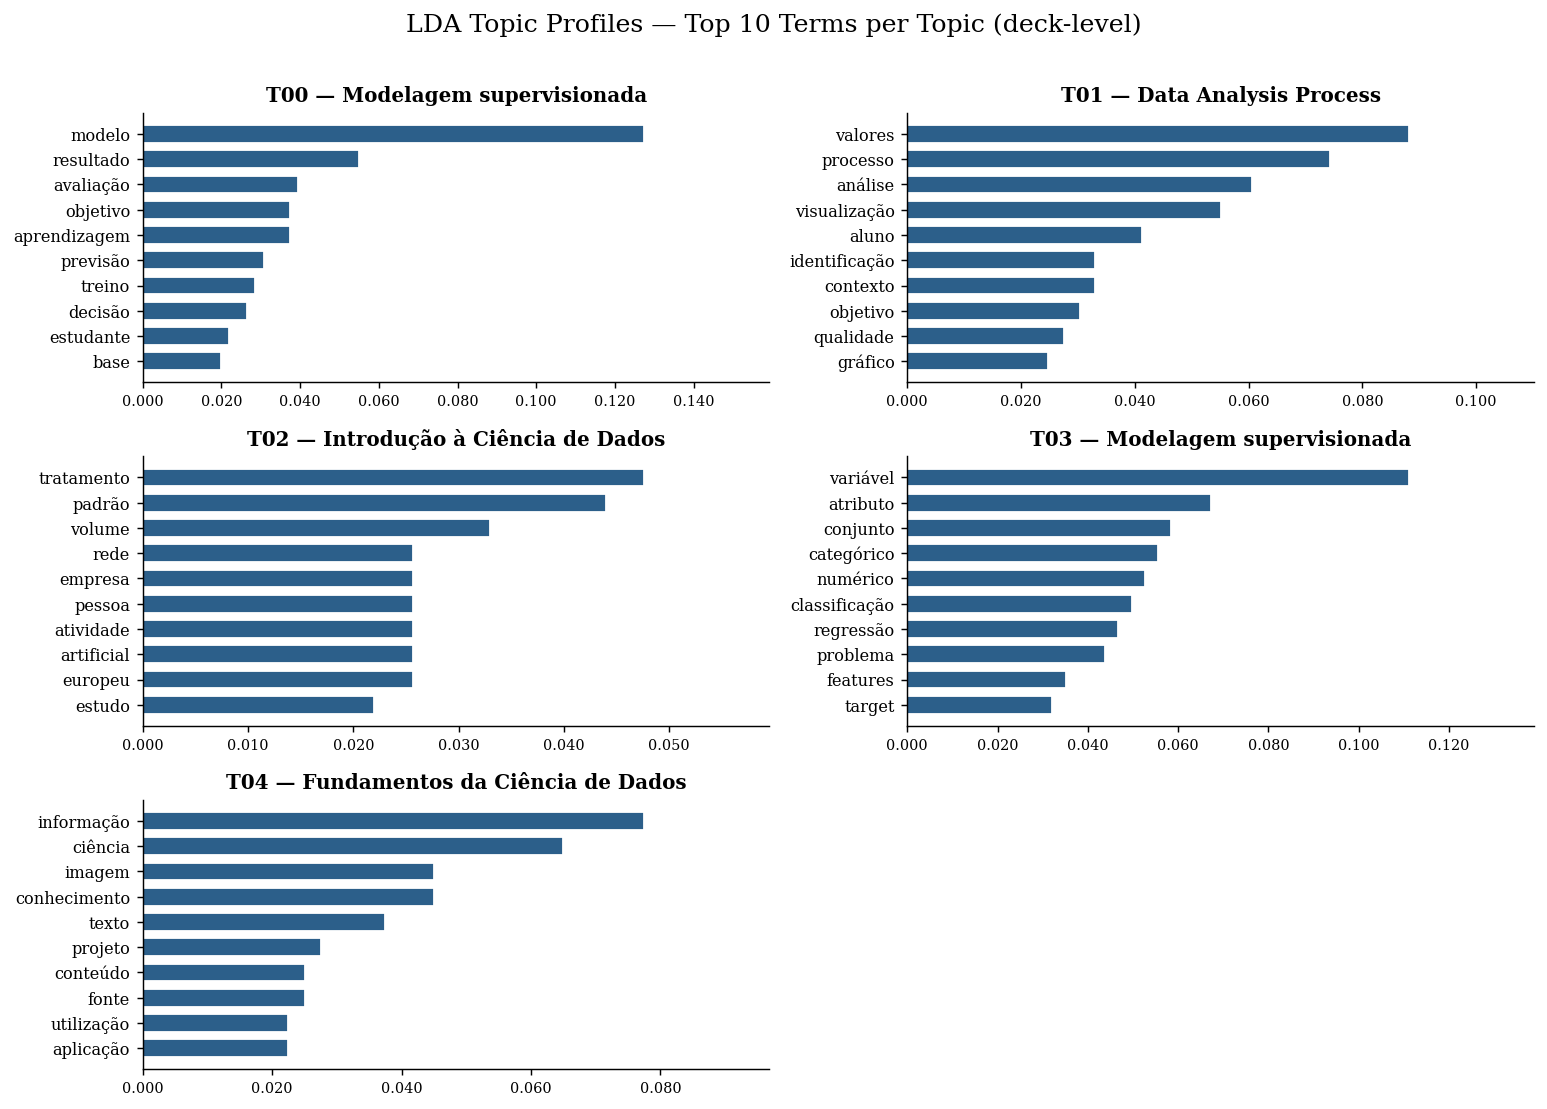

In [9]:
# Visualize topic profiles

TOP_VIS = 10
n_cols = 2
n_rows = (NUM_TOPICS + n_cols - 1) // n_cols

fig, axes = plt.subplots(n_rows, n_cols, figsize=(12, n_rows * 2.8))
axes = axes.flatten()

for i in range(NUM_TOPICS):
    terms   = lda.get_topic_words(i, top_n=TOP_VIS)
    words   = [w for w, _ in terms][::-1]
    weights = [p for _, p in terms][::-1]

    ax = axes[i]
    ax.barh(words, weights, color=PALETTE[0], edgecolor='white', height=0.7)
    ax.set_title(f'T{i:02d} — {TOPIC_LABELS[i]}', fontsize=11, fontweight='bold')
    ax.set_xlim(0, max(weights) * 1.25)
    ax.tick_params(axis='y', labelsize=9)
    ax.tick_params(axis='x', labelsize=8)
    ax.xaxis.set_major_formatter(mticker.FormatStrFormatter('%.3f'))

for j in range(NUM_TOPICS, len(axes)):
    axes[j].set_visible(False)

fig.suptitle('LDA Topic Profiles — Top 10 Terms per Topic (deck-level)', fontsize=14, y=1.01)
plt.tight_layout()
plt.show()

               source_file  n_tokens  dominant_topic
0  icd_2_v1_cleaned_v7.csv       568               2
1  icd_6_v1_cleaned_v7.csv       410               1
2  icd_1_v1_cleaned_v7.csv       488               4
3  icd_9_v1_cleaned_v7.csv       270               4
4  icd_3_v1_cleaned_v7.csv       669               0
5  icd_5_v1_cleaned_v7.csv        58               4
6  icd_4_v1_cleaned_v7.csv       230               1
7  icd_7_v1_cleaned_v7.csv       523               3


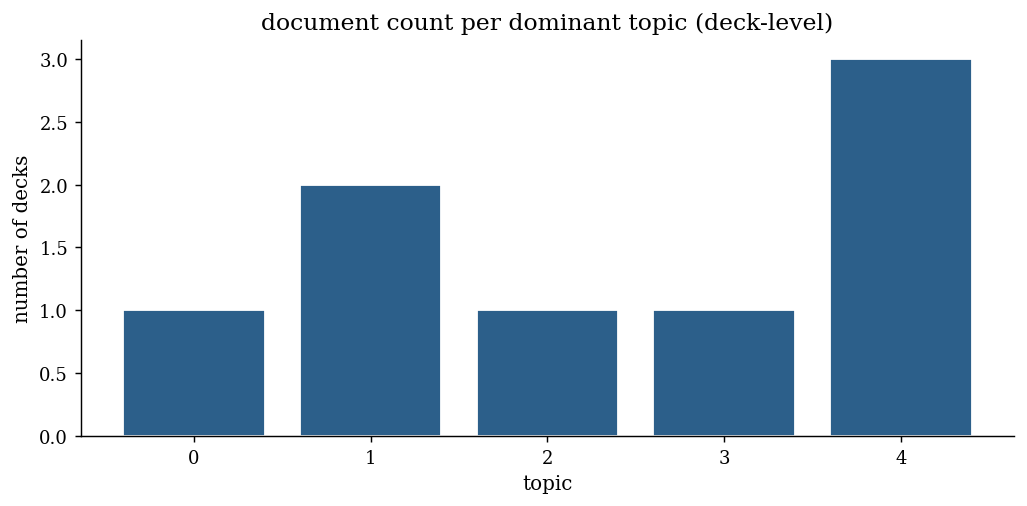

In [10]:
# Visualize document-topic distribution

train_docs_plot = train_docs.copy()
train_docs_plot['dominant_topic'] = [
    int(np.argmax(doc.get_topic_dist())) for doc in lda.docs
]

print(train_docs_plot[['source_file', 'n_tokens', 'dominant_topic']].to_string())

topic_dist = train_docs_plot['dominant_topic'].value_counts().sort_index()

fig, ax = plt.subplots(figsize=(8, 4))
ax.bar(topic_dist.index, topic_dist.values, color=PALETTE[0], edgecolor='white')
ax.set_xlabel('topic')
ax.set_ylabel('number of decks')
ax.set_title('document count per dominant topic (deck-level)')
ax.set_xticks(range(NUM_TOPICS))
plt.tight_layout()
plt.show()

## 5. Evaluation

In [11]:
from utils import compute_holdout_perplexity

# Coherence score (C_v) and perplexity for the current model
coh = Coherence(lda, coherence='c_v')
coherence_cv = coh.get_score()
insample_perp = lda.perplexity
holdout = compute_holdout_perplexity(lda, test_texts)

print(f'Coherence (C_v)          : {coherence_cv:.4f}  (target > 0.50)')
print(f'Perplexity (in-sample)   : {insample_perp:.4f}  [all train docs, biased]')
print(f'Perplexity (holdout)     : {holdout["raw_perplexity"]:.4f}  '
      f'[n_docs={holdout["n_docs"]}, n_words={holdout["n_words"]}]')

Coherence (C_v)          : 0.6165  (target > 0.50)
Perplexity (in-sample)   : 423.3339  [all train docs, biased]
Perplexity (holdout)     : 62.7253  [n_docs=1, n_words=84]


k= 2  C_v=0.5698
k= 3  C_v=0.6534
k= 4  C_v=0.6023
k= 5  C_v=0.6165
k= 6  C_v=0.5715
k= 7  C_v=0.6131
k= 8  C_v=0.6205


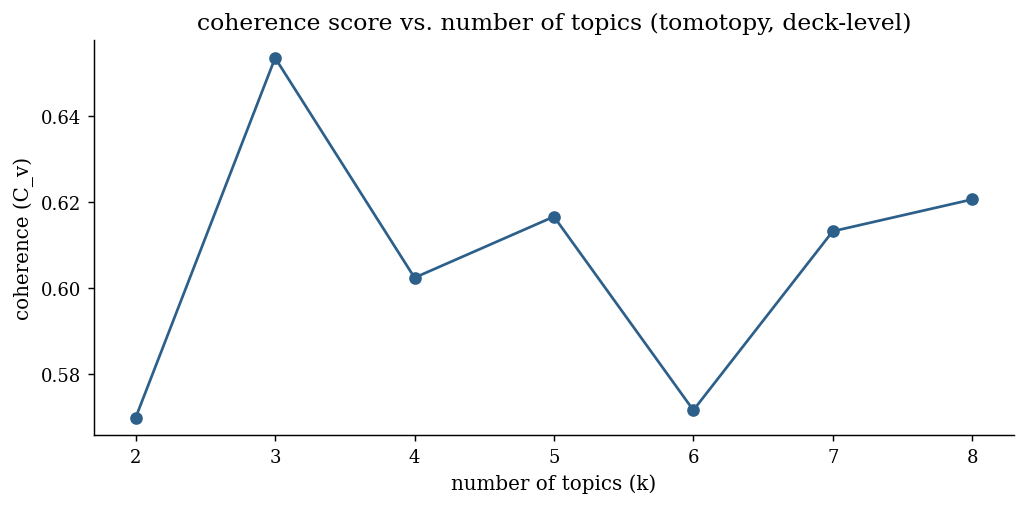


Best k=3  C_v=0.6534


In [12]:
# Coherence grid search over number of topics
# Helps to find the optimal K before committing to a final model and parameters.

TOPIC_RANGE = range(2, 9)

results = []
for k in TOPIC_RANGE:
    m = tp.LDAModel(k=k, alpha=ALPHA, eta=ETA, min_df=2, rm_top=0, seed=RANDOM_SEED)
    for token_list in train_texts:
        m.add_doc(token_list)
    m.train(0)
    m.train(ITERATIONS, workers=1)
    cv = Coherence(m, coherence='c_v').get_score()
    results.append({'k': k, 'coherence_cv': round(cv, 4)})
    print(f'k={k:2d}  C_v={cv:.4f}')

results_df = pd.DataFrame(results)

fig, ax = plt.subplots(figsize=(8, 4))
ax.plot(results_df['k'], results_df['coherence_cv'], marker='o', color=PALETTE[0])
ax.set_xlabel('number of topics (k)')
ax.set_ylabel('coherence (C_v)')
ax.set_title('coherence score vs. number of topics (tomotopy, deck-level)')
ax.set_xticks(list(TOPIC_RANGE))
plt.tight_layout()
plt.show()

best = results_df.loc[results_df['coherence_cv'].idxmax()]
print(f'\nBest k={int(best.k)}  C_v={best.coherence_cv}')

## 6. Optimized K's

Original K: `NUM_TOPICS = 5`. Avoids trivial overfitting.
Re-train with **K=3** for a more conservative deck-level baseline in both libraries.

> **Note:** With only 9 documents, deck-level LDA is below the statistical sweet spot for topic models; results in this section are exploratory. Cross-library K cross-application is also skipped here because K=3 is already the chosen value for both deck-level notebooks.

In [13]:
# Multi-K sweep: train one model per K in K_GRID and store them in `models_by_k`.
# K_GRID covers the initial guess and each library's grid-search optimum.
K_GRID = [5, 3]
K_INITIAL = 5  
K_OWN_BEST = 3            


models_by_k = {K_INITIAL: lda}
for k in K_GRID:
    if k in models_by_k:
        continue
    m = tp.LDAModel(
        k        = k,
        alpha    = ALPHA,
        eta      = ETA,
        min_df   = 2,
        rm_top   = 0,
        seed     = RANDOM_SEED,
    )
    for token_list in train_texts:
        m.add_doc(token_list)
    m.train(0)
    m.train(ITERATIONS, workers=1)
    models_by_k[k] = m
    print(f'-- trained tomotopy LDA at k={k}, seed={RANDOM_SEED}')

lda_new = models_by_k[K_OWN_BEST]
NUM_TOPICS_NEW = K_OWN_BEST

TOP_N_NEW = 10
for k, m in models_by_k.items():
    print(f'\n=== k={k} top terms ===')
    for i in range(k):
        if hasattr(m, 'show_topic'):
            terms = m.show_topic(i, topn=TOP_N_NEW)
        else:
            terms = m.get_topic_words(i, top_n=TOP_N_NEW)
        term_str = ' + '.join(f'{p:.3f}*"{w}"' for w, p in terms)
        print(f'Topic {i:02d}: {term_str}')

TOPIC_LABELS_NEW = generate_topic_labels_llm(lda_new, NUM_TOPICS_NEW)
print()
for idx, label in TOPIC_LABELS_NEW.items():
    print(f'T{idx:02d}: {label}')


-- trained tomotopy LDA at k=3, seed=42

=== k=5 top terms ===
Topic 00: 0.127*"modelo" + 0.055*"resultado" + 0.040*"avaliação" + 0.037*"objetivo" + 0.037*"aprendizagem" + 0.031*"previsão" + 0.029*"treino" + 0.026*"decisão" + 0.022*"estudante" + 0.020*"base"
Topic 01: 0.088*"valores" + 0.074*"processo" + 0.061*"análise" + 0.055*"visualização" + 0.041*"aluno" + 0.033*"identificação" + 0.033*"contexto" + 0.030*"objetivo" + 0.028*"qualidade" + 0.025*"gráfico"
Topic 02: 0.048*"tratamento" + 0.044*"padrão" + 0.033*"volume" + 0.026*"rede" + 0.026*"empresa" + 0.026*"pessoa" + 0.026*"atividade" + 0.026*"artificial" + 0.026*"europeu" + 0.022*"estudo"
Topic 03: 0.111*"variável" + 0.067*"atributo" + 0.058*"conjunto" + 0.056*"categórico" + 0.053*"numérico" + 0.050*"classificação" + 0.047*"regressão" + 0.044*"problema" + 0.035*"features" + 0.032*"target"
Topic 04: 0.077*"informação" + 0.065*"ciência" + 0.045*"imagem" + 0.045*"conhecimento" + 0.038*"texto" + 0.028*"projeto" + 0.025*"conteúdo" + 0.02


T00: Modelagem Supervisionada
T01: Preparação de dados
T02: Visualização e interpretação de dados


## 7. Extended metrics

Complementary metrics are reported for **every** K in the sweep, each capturing a different aspect of model quality. Used together, they expose trade-offs that any single number would conceal.

- **C_v coherence (primary).** expecting the chosen K to score above 0.50 and to rank higher than alternatives, confirming that top words within each topic are semantically related.

- **U_mass coherence (secondary).** expecting its relative ranking across K values to agree with C_v, confirming that coherence differences are not artefacts of the external reference corpus.

- **Unified perplexity.** expecting perplexity to decrease as K increases, but values should be read alongside coherence since a lower perplexity does not guarantee interpretable topics.

- **Topic diversity (Dieng et al. 2020).** expecting diversity to remain high (close to 1), indicating that topics are not redundantly recycling the same high-frequency words.

- **Mean pairwise topic cosine similarity.** expecting low mean cosine similarity (well below 1), indicating that topic word-distributions are spread across distinct regions of the vocabulary.

- **Mean Shannon entropy of topic-word distributions.** expecting low normalised entropy, indicating that each topic concentrates probability mass on a small, coherent set of words rather than spreading it diffusely across the vocabulary.

The metrics for every K are persisted as JSON under `data/output/<notebook>_metrics.json` for the cross-notebook comparison in `lda_comparison_v2.ipynb`.

In [14]:
# Compute extended metrics for every K in K_GRID and persist as JSON.
import json, os
from utils import (
    compute_topic_diversity,
    compute_topic_cosine_similarity,
    compute_topic_entropy,
    unify_perplexity,
    compute_holdout_perplexity,
    OUTPUT_ROOT,
)

K_ROLE = {5: 'initial', 3: 'own_library_best'}

def _metrics(m, k):
    out = {}
    for coh_kind in ('c_v', 'u_mass'):
        out[f'coherence_{coh_kind}'] = float(Coherence(m, coherence=coh_kind).get_score())
    pp = unify_perplexity(m, bow_corpus=None)
    out['raw_perplexity'] = pp['raw_perplexity']
    out['log_perplexity'] = pp['log_perplexity']
    ho = compute_holdout_perplexity(m, test_texts)
    out['holdout_raw_perplexity'] = ho['raw_perplexity']
    out['holdout_log_perplexity'] = ho['log_perplexity']
    out['holdout_n_docs']         = ho['n_docs']
    out['holdout_n_words']        = ho['n_words']
    vocab_size = m.num_vocabs if hasattr(m, 'num_vocabs') else len(m.id2word)
    out['topic_diversity_top25'] = compute_topic_diversity(
        m, k, n=25, vocab_size=vocab_size
    )
    cos = compute_topic_cosine_similarity(m, k)
    out['cosine_similarity_mean'] = cos['mean']
    out['cosine_similarity_max']  = cos['max']
    ent = compute_topic_entropy(m, k)
    out['shannon_entropy_mean']      = ent['mean']
    out['shannon_entropy_mean_norm'] = ent['mean_norm']
    out['topic_labels'] = {
        i: lbl for i, lbl in generate_topic_labels_llm(m, k).items()
    }
    out['k'] = int(k)
    out['role'] = K_ROLE.get(k, 'extra')
    return out

configs = [_metrics(m, k) for k, m in models_by_k.items()]

rows = []
for cfg_metrics in configs:
    rows.append({
        'role'                   : cfg_metrics['role'],
        'k'                      : cfg_metrics['k'],
        'coherence_c_v'          : cfg_metrics['coherence_c_v'],
        'coherence_u_mass'       : cfg_metrics['coherence_u_mass'],
        'raw_perplexity'         : cfg_metrics['raw_perplexity'],
        'holdout_raw_perplexity' : cfg_metrics['holdout_raw_perplexity'],
        'topic_diversity'        : cfg_metrics['topic_diversity_top25']['diversity'],
        'cosine_similarity'      : cfg_metrics['cosine_similarity_mean'],
        'shannon_entropy'        : cfg_metrics['shannon_entropy_mean'],
    })

metrics_df = pd.DataFrame(rows).set_index('role')
print('Extended metrics across K_GRID:')
display(metrics_df.style.format({
    'coherence_c_v': '{:.4f}', 'coherence_u_mass': '{:.4f}',
    'raw_perplexity': '{:.2f}', 'holdout_raw_perplexity': '{:.2f}',
    'topic_diversity': '{:.4f}', 'cosine_similarity': '{:.4f}',
    'shannon_entropy': '{:.4f}',
}))

by_role = {c['role']: c for c in configs}
metrics_payload = {
    'notebook': 'lda_v4',
    'library': 'tomotopy',
    'granularity': 'deck',
    'n_documents': int(len(docs)),
    'n_documents_train': len(train_texts),
    'n_documents_test':  len(test_texts),
    'vocab_size': int(list(models_by_k.values())[0].num_vocabs) if hasattr(list(models_by_k.values())[0], 'num_vocabs') else int(len(list(models_by_k.values())[0].id2word)),
    'random_seed': RANDOM_SEED,
    'k_grid': K_GRID,
    'configs': configs,
    'old_K': by_role['initial'],
    'new_K': by_role.get('own_library_best', by_role['initial']),
    'grid_search': results_df.to_dict(orient='records'),
}
json_path = os.path.join(OUTPUT_ROOT, 'lda_v4' + '_metrics.json')
os.makedirs(OUTPUT_ROOT, exist_ok=True)
with open(json_path, 'w') as f:
    json.dump(metrics_payload, f, indent=2)
print(f'Metrics written to: {json_path}')

Extended metrics across K_GRID:


,k,coherence_c_v,coherence_u_mass,raw_perplexity,holdout_raw_perplexity,topic_diversity,cosine_similarity,shannon_entropy
role,,,,,,,,
initial,5,0.6165,-0.4645,423.33,62.73,0.9840,0.0171,3.9428
own_library_best,3,0.6534,-0.4498,417.16,56.90,1.0000,0.0120,4.3500


Metrics written to: /Users/I749701/Developer/University/MIGThesis-126735/data/output/lda_v4_metrics.json
